# A day of the ionosphere from GNSS phase differences


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`time`，shape `(1, 504358)`，dtype `<f8`：Current ray time, seconds after midnight；`mlt1`，shape `(1, 504358)`，dtype `<f8`：Current 450 km shell local-time longitude, rad；`mcolat1`，shape `(1, 504358)`，dtype `<f8`：Current MODIP colatitude, rad；`el`，shape `(1, 504358)`，dtype `<f8`：Current receiver elevation, rad；`time_ref`，shape `(1, 504358)`，dtype `<f8`：Paired reference time, seconds after midnight；`mlt1_ref`，shape `(1, 504358)`，dtype `<f8`：Reference shell local-time longitude, rad；`mcolat1_ref`，shape `(1, 504358)`，dtype `<f8`：Reference MODIP colatitude, rad；`el_ref`，shape `(1, 504358)`，dtype `<f8`：Reference receiver elevation, rad；`rhs`，shape `(1, 504358)`，dtype `<f8`：Measured current-minus-reference slant TEC, TECu；`grid_colatitude`，shape `(1, 71)`，dtype `<f8`：Output MODIP colatitude coordinates, rad；`grid_longitude`，shape `(1, 72)`，dtype `<f8`：Output local-time longitude coordinates, rad；`grid_time`，shape `(1, 25)`，dtype `<f8`：Output hourly time coordinates, s。未知量为25小时节点全球71×72垂直TEC场。

获取模型：薄壳倾斜因子乘VTEC的当前/参考射线差产生GNSS相位导出的斜TEC差。

如何恢复：src.solvers.reconstruct：全射线球谐/时间系数正规方程及单次负网格节点LCP校正。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3观测覆盖；6全程恢复；8观测残差/参考场；9/11时间先验及非负校正实验；13 Judge。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留5个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


This active review reconstructs **all 504358 real ray pairs from all313 author-provided station directories**, then evaluates every sample of a25×71×72 vertical-TEC field. The independently executed author method is a **conditional reference, not electron-content truth**. All fresh curves and maps below are calculated in this execution using local `src` mathematics.

## 1. Problem: see a global layer through moving radio paths

Dual-frequency carrier phase is sensitive to integrated electron content. A receiver/satellite arc has an unknown additive phase ambiguity, so the measured quantity is a current-minus-reference slant-TEC difference. The target is a complete global vertical-TEC field, not a fitted scalar or a direct3D altitude-density measurement. One TECu is $10^{16}$ electrons/m². Ocean coverage, unknown absolute phase and the thin-shell approximation limit physical interpretation.

In [1]:
from pathlib import Path
import os, sys, time, json, hashlib, tempfile, importlib.util
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():
    ROOT=ROOT.parent if (ROOT.parent/'src').is_dir() else ROOT
assert (ROOT/'src').is_dir()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.physics_model import (real_harmonics,slant_factor,grid_basis,render_maps,predict,
                               residual_metrics,temporal_precision,design_matrix)
from src.solvers import assemble_normal_system,solve_system
from src.visualization import map_metrics,save_figure
FIG=Path(os.environ.get('IMAGING_FIGURE_DIR',str(Path(tempfile.gettempdir())/'gnss_review_figures')))
FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,
                     'figure.dpi':110,'savefig.facecolor':'white'})
environment={'executable':sys.executable,'numpy':np.__version__,'scipy':scipy.__version__,
 'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),
 'OMP_NUM_THREADS':os.environ.get('OMP_NUM_THREADS'),'OPENBLAS_NUM_THREADS':os.environ.get('OPENBLAS_NUM_THREADS')}
print(json.dumps(environment,indent=2))
data,grids=load_data(ROOT/'data/raw_data.npz')
original=np.load(ROOT/'notebooks/reference_outputs/upstream_outputs.npz',allow_pickle=False)
print('Real ray pairs:',len(data['rhs']),'UTC day:2017-01-02; output nodes:',grids['grid_time']/3600)


{
  "executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "module://matplotlib_inline.backend_inline",
  "OMP_NUM_THREADS": "1",
  "OPENBLAS_NUM_THREADS": "1"
}
Real ray pairs: 504358 UTC day:2017-01-02; output nodes: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24.]


## 2. Data: calibrated pierce points, not uniformly sampled pixels

The visible data are the author's phase-derived observations after arc screening and600s decimation. Minimum-TEC reference selection cancels each arc's additive ambiguity. The selected450km shell uses **MODIP colatitude and local-time longitude**, already calibrated independently of the unknown target. These are not geographic station positions.

The entire provided test package is used; it contains313GPS/GLONASS stations, whereas the article's example uses286GPS stations. The executable preprocessing does **not** apply its paper-described Savitzky–Golay smoothing step. No new noise, interpolation, observation clipping or postfit quality mask is introduced. Zero-count bins in the coverage image are white; they do not mark uncomputed reconstruction pixels.

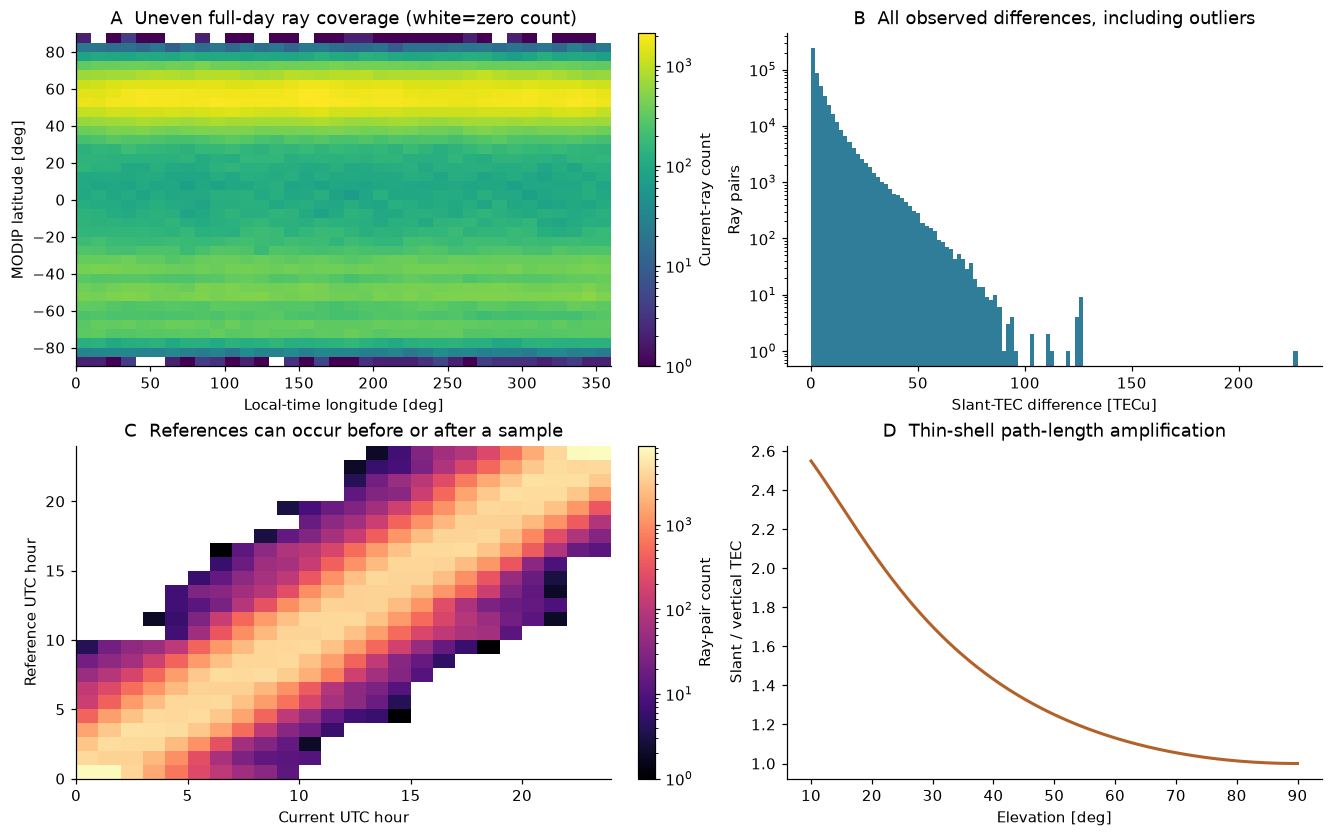

In [2]:
coverage,_,_=np.histogram2d(np.rad2deg(data['mcolat1']),np.rad2deg(data['mlt1']),bins=[np.arange(0,181,5),np.arange(0,361,10)])
pair_counts,_,_=np.histogram2d(data['time']/3600,data['time_ref']/3600,bins=[np.arange(25),np.arange(25)])
ray_hour=np.histogram(data['time']/3600,bins=np.arange(25))[0]
fig,ax=plt.subplots(2,2,figsize=(12,7.5),layout='constrained')
im=ax[0,0].imshow(np.ma.masked_equal(coverage,0),extent=[0,360,-90,90],origin='upper',aspect='auto',norm=LogNorm(vmin=1,vmax=coverage.max()),cmap='viridis')
fig.colorbar(im,ax=ax[0,0],label='Current-ray count');ax[0,0].set(title='A  Uneven full-day ray coverage (white=zero count)',xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
ax[0,1].hist(data['rhs'],bins=120,color='#307d99',log=True);ax[0,1].set(title='B  All observed differences, including outliers',xlabel='Slant-TEC difference [TECu]',ylabel='Ray pairs')
im=ax[1,0].imshow(np.ma.masked_equal(pair_counts.T,0),origin='lower',extent=[0,24,0,24],aspect='auto',norm=LogNorm(vmin=1,vmax=pair_counts.max()),cmap='magma')
fig.colorbar(im,ax=ax[1,0],label='Ray-pair count');ax[1,0].set(title='C  References can occur before or after a sample',xlabel='Current UTC hour',ylabel='Reference UTC hour')
e=np.deg2rad(np.linspace(10,90,300));ax[1,1].plot(np.rad2deg(e),slant_factor(e),color='#b26228',lw=2)
ax[1,1].set(title='D  Thin-shell path-length amplification',xlabel='Elevation [deg]',ylabel='Slant / vertical TEC')
save_figure(fig,FIG,'figure1_observations');plt.show()


## 3. Physics: a spatial field with continuous hourly coefficients

For measured ray pair $i$,
$$y_i=s(e_i)V(t_i,\lambda_i,\theta_i)-s(e_i^{r})V(t_i^{r},\lambda_i^{r},\theta_i^{r})+\epsilon_i,$$
$$s(e)=\left[1-\left(\frac{R\cos e}{R+h}\right)^2\right]^{-1/2},\qquad R=6371000\,\mathrm m,\ h=450000\,\mathrm m.$$
Here $y$ and vertical field $V$ are in TECu, $e$ is elevation, $t$ is seconds after midnight, $\lambda$ is local-time longitude, $\theta$ is MODIP colatitude, superscript$r$ is the reference ray, and $\epsilon$ is error. Angles are radians.

Write $V=\sum_{n=0}^{15}\sum_{m=-n}^{n}c_{nm}(t)H_{nm}(\lambda,\theta)$. The real orthonormal basis$H$ is formed from normalized complex harmonics$Y=aP_n^{|m|}(\cos\theta)\exp(i|m|\lambda)$: negative orders use$\sqrt2(-1)^m\operatorname{Im}Y$, positive orders use$\sqrt2(-1)^m\operatorname{Re}Y$, zero order uses$\operatorname{Re}Y$. The normalization is$a=\sqrt{(2n+1)(n-|m|)!/[4\pi(n+|m|)!]}$, with Condon–Shortley associated Legendre polynomials$P$. There are256modes per hour and6400coefficients$c$ in TECu.

At fractional hour$u$ between nodes$j$ and$j+1$, use$(1-u)c_j+uc_{j+1}$. The private qualified original restores four reversed source factors to this continuous interpolation. Independent ramp/constant/node-continuity tests precede local extraction; the unmodified result is preserved as an explicitly different control.

In the complex exponential, $i$ denotes the imaginary unit with $i^2=-1$, distinct from an observation subscript.

## 4. Method: conditional global fit, followed by the author's one-pass LCP

With differenced ray operator$A$, observations$y$, adjacent-hour first difference$D$ and diagonal weights$W$, minimize
$$J(c)=(Ac-y)^TW(Ac-y)+\sigma_{rel}^{-2}\|Dc\|_2^2,$$
$$W_{ii}=\sigma_0^{-2}\frac{\sin^2e_i\sin^2e_i^r}{\sin^2e_i+\sin^2e_i^r},\quad\sigma_0=.02\ \mathrm{TECu},\quad\sigma_{rel}=.005\ \mathrm{TECu}.$$
These are selected conditional scales, not an empirical noise calibration; shared-reference correlations are not modeled. Set$N=A^TWA+\sigma_{rel}^{-2}D^TD$, $b=A^TWy$, and$c_0=N^{-1}b$. No half factor or observation-count normalization is implicit.

Let$G$ evaluate all127800grid nodes and$G_s$ contain only rows where$Gc_0<0$. The source solves$z\ge0$, $Mz+q\ge0$, $z^T(Mz+q)=0$, with$M=G_sN^{-1}G_s^T$ and$q=G_sc_0$, then returns$c=c_0+N^{-1}G_s^Tz$. The local Lemke tableau implements the initialization, elimination, complementary pivots, strict ratio tie rule and stopping conditions explicitly. This one-pass approximation can create a new small negative value at another node. It is not strict full-grid positivity.

The following cell actively assembles **all168normal-system chunks** and runs the complete selected inverse path. It does not load a reconstruction cache.

normal chunks 1/168


normal chunks 26/168


normal chunks 51/168


normal chunks 76/168


normal chunks 101/168


normal chunks 126/168


normal chunks 151/168


normal chunks 168/168


{
  "active_full_runtime_seconds": 638.4888620999991,
  "all_output_samples": 127800,
  "min_hour_ncc": 0.9999999999999999,
  "max_hour_range_nrmse": 7.278529375998845e-15,
  "minimum_signed_TECu": -0.011068219960897352,
  "maximum_TECu": 49.48745380145722,
  "source_dispersion_not_empirical_noise": 1138.4473898023152
}


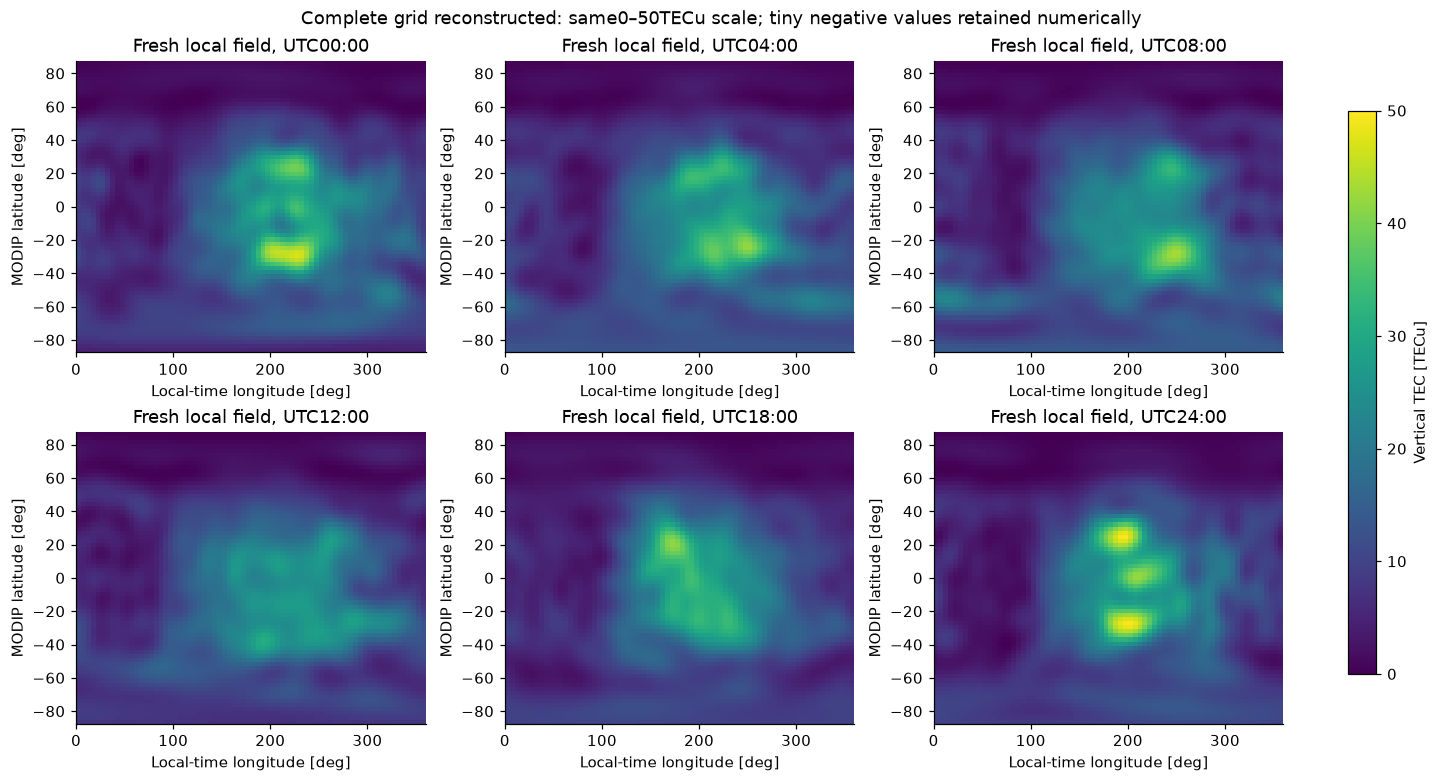

In [3]:
started=time.perf_counter()
N,b,rPr,dof=assemble_normal_system(data,progress=True)
fresh=solve_system(N,b,rPr,dof)
maps=render_maps(fresh['coefficients'])
active_runtime=time.perf_counter()-started
np.savez(ROOT/'output/reconstruction.npz',reconstruction=maps[None])
ncc,nrmse=map_metrics(maps,original['qualified'])
print(json.dumps({'active_full_runtime_seconds':active_runtime,'all_output_samples':maps.size,
 'min_hour_ncc':float(ncc.min()),'max_hour_range_nrmse':float(nrmse.max()),
 'minimum_signed_TECu':float(maps.min()),'maximum_TECu':float(maps.max()),
 'source_dispersion_not_empirical_noise':fresh['dispersion']},indent=2))
assert ncc.min()>=.999999999999 and nrmse.max()<=2.9645042444036815e-8
fig,ax=plt.subplots(2,3,figsize=(13,7),layout='constrained')
for a,j in zip(ax.flat,[0,4,8,12,18,24]):
 im=a.imshow(maps[j],origin='upper',extent=[0,360,-87.5,87.5],aspect='auto',vmin=0,vmax=50,cmap='viridis')
 a.set(title=f'Fresh local field, UTC{j:02d}:00',xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
fig.colorbar(im,ax=ax,label='Vertical TEC [TECu]',shrink=.85)
fig.suptitle('Complete grid reconstructed: same0–50TECu scale; tiny negative values retained numerically')
save_figure(fig,FIG,'figure2_global_field');plt.show()


## 5. Results: reference agreement and physical residuals answer different questions

Reference agreement tests extraction and numerical fidelity. Each hour is scored independently with its own reference range. Cosine NCC is the uncentered flattened dot product divided by the two norms; NRMSE is RMS error divided by that hour's maximum-minus-minimum. The nonzero threshold was fixed from two independent complete source runs and measured float32 coefficient-serialization sensitivity before local scoring. It is not a statement of physical accuracy.

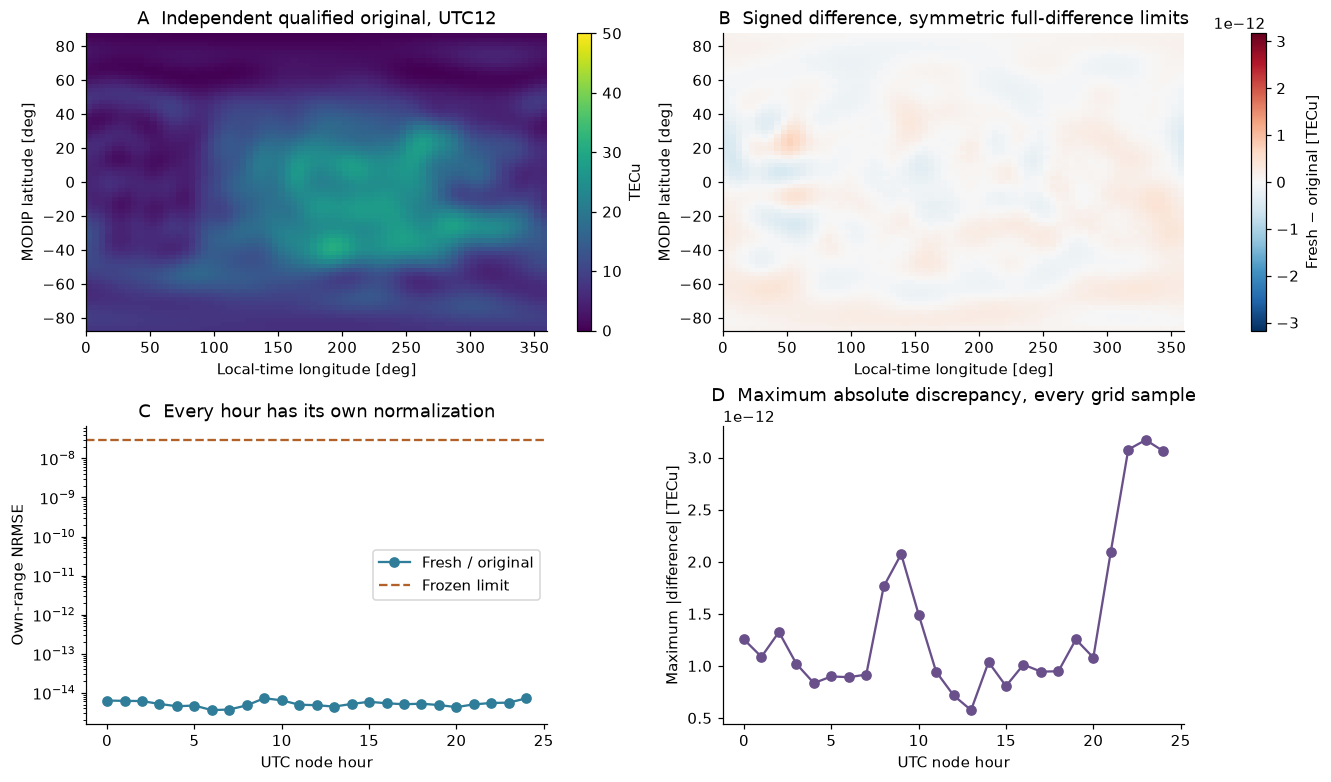

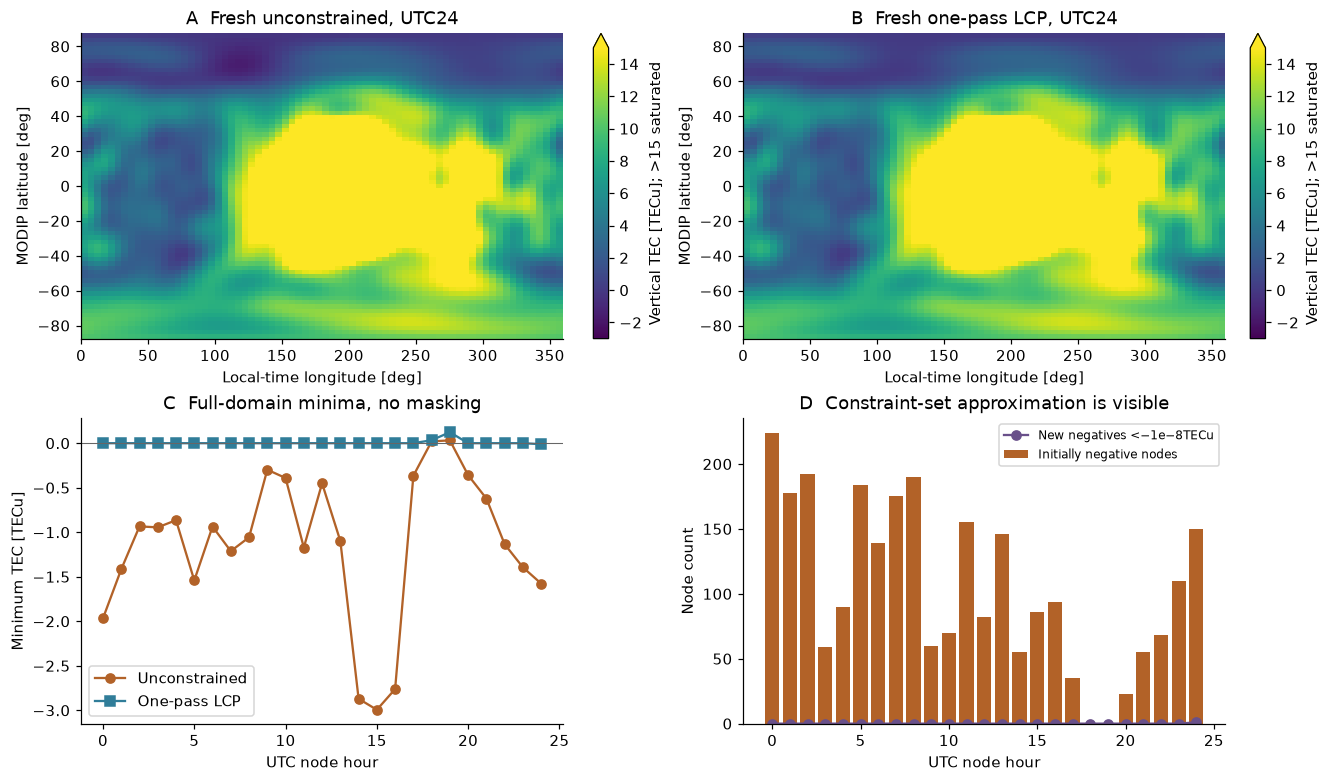

Initially constrained: 2620 new negative nodes: 1 minimum retained: -0.011068219960897352


In [4]:
delta=maps-original['qualified'];span=max(float(abs(delta).max()),1e-14)
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
im=ax[0,0].imshow(original['qualified'][12],extent=[0,360,-87.5,87.5],aspect='auto',vmin=0,vmax=50,cmap='viridis');fig.colorbar(im,ax=ax[0,0],label='TECu')
ax[0,0].set(title='A  Independent qualified original, UTC12',xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
im=ax[0,1].imshow(delta[12],extent=[0,360,-87.5,87.5],aspect='auto',norm=TwoSlopeNorm(vmin=-span,vcenter=0,vmax=span),cmap='RdBu_r');fig.colorbar(im,ax=ax[0,1],label='Fresh − original [TECu]')
ax[0,1].set(title='B  Signed difference, symmetric full-difference limits',xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
ax[1,0].semilogy(np.arange(25),np.maximum(nrmse,1e-18),'o-',color='#307d99',label='Fresh / original')
ax[1,0].axhline(2.9645042444036815e-8,color='#b26228',ls='--',label='Frozen limit')
ax[1,0].set(title='C  Every hour has its own normalization',xlabel='UTC node hour',ylabel='Own-range NRMSE');ax[1,0].legend()
ax[1,1].plot(np.arange(25),np.max(abs(delta),axis=(1,2)),'o-',color='#69508a')
ax[1,1].set(title='D  Maximum absolute discrepancy, every grid sample',xlabel='UTC node hour',ylabel='Maximum |difference| [TECu]')
save_figure(fig,FIG,'figure3_source_parity');plt.show()
uncon_maps=render_maps(fresh['unconstrained_coefficients']);correction=maps-uncon_maps
initial_negative=uncon_maps<0;new_negative=(maps< -1e-8)&~initial_negative
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for a,arr,title in [(ax[0,0],uncon_maps[24],'A  Fresh unconstrained, UTC24'),(ax[0,1],maps[24],'B  Fresh one-pass LCP, UTC24')]:
 im=a.imshow(arr,extent=[0,360,-87.5,87.5],aspect='auto',vmin=-3,vmax=15,cmap='viridis');fig.colorbar(im,ax=a,label='Vertical TEC [TECu]; >15 saturated',extend='max');a.set(title=title,xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
ax[1,0].plot(np.arange(25),uncon_maps.min(axis=(1,2)),'o-',label='Unconstrained',color='#b26228')
ax[1,0].plot(np.arange(25),maps.min(axis=(1,2)),'s-',label='One-pass LCP',color='#307d99');ax[1,0].axhline(0,color='.4',lw=.7)
ax[1,0].set(title='C  Full-domain minima, no masking',xlabel='UTC node hour',ylabel='Minimum TEC [TECu]');ax[1,0].legend()
ax[1,1].bar(np.arange(25),np.sum(initial_negative,axis=(1,2)),color='#b26228',label='Initially negative nodes')
ax[1,1].plot(np.arange(25),np.sum(new_negative,axis=(1,2)),'o-',color='#69508a',label='New negatives <−1e−8TECu')
ax[1,1].set(title='D  Constraint-set approximation is visible',xlabel='UTC node hour',ylabel='Node count');ax[1,1].legend(fontsize=8)
save_figure(fig,FIG,'figure4_constraint_ablation');plt.show()
print('Initially constrained:',initial_negative.sum(),'new negative nodes:',new_negative.sum(),'minimum retained:',maps.min())


{
  "Fresh constrained": {
    "rms_TECu": 2.0273588766874897,
    "weighted_rms_TECu": 1.497351780662863
  },
  "Fresh unconstrained": {
    "rms_TECu": 2.0267150627648154,
    "weighted_rms_TECu": 1.4960235399770498
  },
  "Original wrong-time field, correct forward": {
    "rms_TECu": 2.419891222909127,
    "weighted_rms_TECu": 1.8132918114752796
  },
  "Best uniform field": {
    "rms_TECu": 7.929632321239453,
    "weighted_rms_TECu": 5.263030157972085
  },
  "Zero field": {
    "rms_TECu": 8.670855709304101,
    "weighted_rms_TECu": 5.922949979638512
  }
}


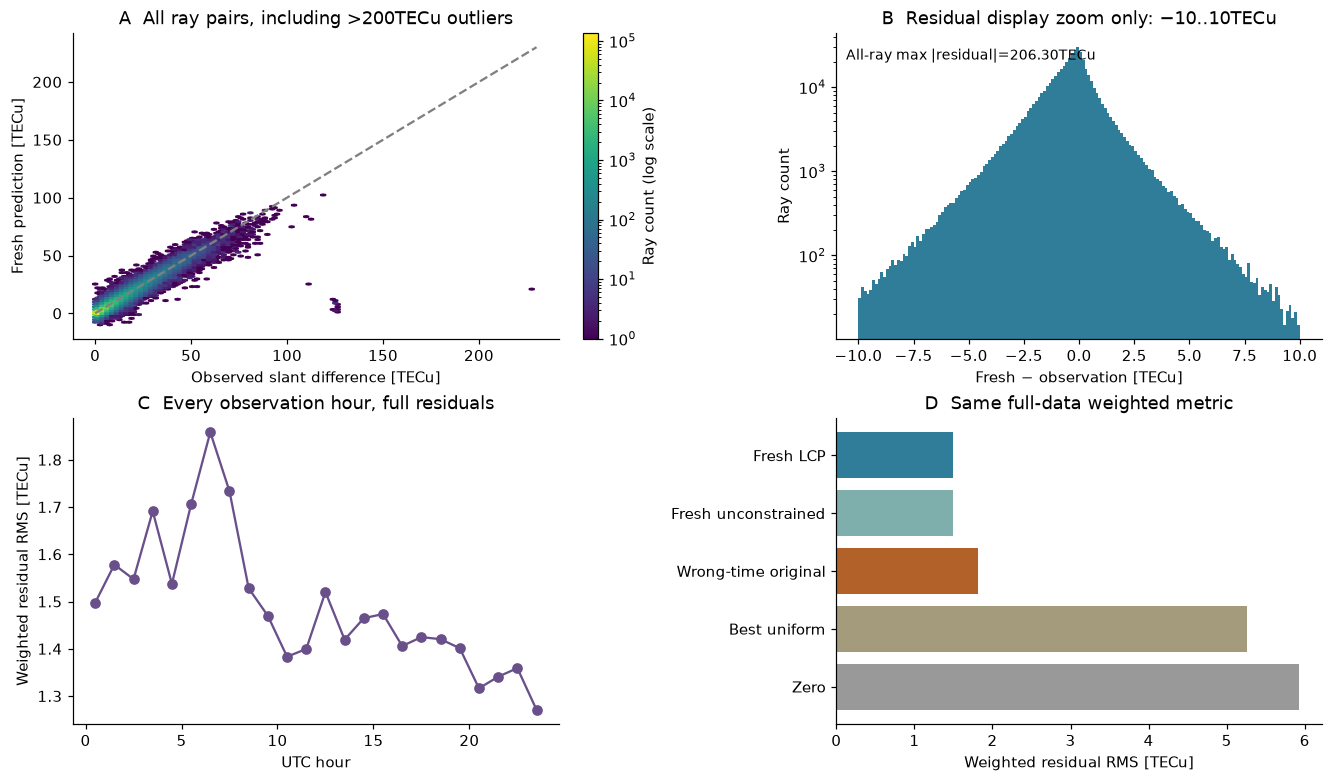

In [5]:
pred=predict(fresh['coefficients'],data)
pred_uncon=predict(fresh['unconstrained_coefficients'],data)
pred_wrong=predict(original['wrong_time_coefficients'],data)
sin2=np.sin(data['el'])**2;sinr2=np.sin(data['el_ref'])**2;w=sin2*sinr2/(sin2+sinr2)
uniform_response=(slant_factor(data['el'])-slant_factor(data['el_ref']))/np.sqrt(4*np.pi)
uniform_coefficient=np.dot(w*uniform_response,data['rhs'])/np.dot(w*uniform_response,uniform_response)
pred_uniform=uniform_response*uniform_coefficient
comparison_predictions={'Fresh constrained':pred,'Fresh unconstrained':pred_uncon,
 'Original wrong-time field, correct forward':pred_wrong,'Best uniform field':pred_uniform,
 'Zero field':np.zeros_like(pred)}
comparison_metrics={key:residual_metrics(value,data) for key,value in comparison_predictions.items()}
print(json.dumps(comparison_metrics,indent=2))
assert residual_metrics(pred,data)['weighted_rms_TECu']<=1.5272988162761219
hour_rms=[]
for h in range(24):
 select=(data['time']>=3600*h)&(data['time']<3600*(h+1));e=(pred-data['rhs'])[select];ww=w[select]
 hour_rms.append(float(np.sqrt(np.dot(ww,e**2)/ww.sum())))
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
h=ax[0,0].hexbin(data['rhs'],pred,gridsize=90,mincnt=1,bins='log',cmap='viridis');fig.colorbar(h,ax=ax[0,0],label='Ray count (log scale)')
ax[0,0].plot([0,230],[0,230],'--',color='.5');ax[0,0].set(title='A  All ray pairs, including >200TECu outliers',xlabel='Observed slant difference [TECu]',ylabel='Fresh prediction [TECu]')
ax[0,1].hist(pred-data['rhs'],bins=160,range=(-10,10),color='#307d99',log=True)
ax[0,1].set(title='B  Residual display zoom only: −10..10TECu',xlabel='Fresh − observation [TECu]',ylabel='Ray count');ax[0,1].text(.02,.95,f'All-ray max |residual|={abs(pred-data["rhs"]).max():.2f}TECu',transform=ax[0,1].transAxes,va='top',fontsize=9)
ax[1,0].plot(np.arange(24)+.5,hour_rms,'o-',color='#69508a');ax[1,0].set(title='C  Every observation hour, full residuals',xlabel='UTC hour',ylabel='Weighted residual RMS [TECu]')
names=list(comparison_metrics);vals=[comparison_metrics[key]['weighted_rms_TECu'] for key in names]
ax[1,1].barh(np.arange(len(vals)),vals,color=['#307d99','#7eafac','#b26228','#a49a7c','#999999'])
ax[1,1].set_yticks(np.arange(len(vals)),['Fresh LCP','Fresh unconstrained','Wrong-time original','Best uniform','Zero']);ax[1,1].invert_yaxis();ax[1,1].set(title='D  Same full-data weighted metric',xlabel='Weighted residual RMS [TECu]')
save_figure(fig,FIG,'figure5_observation_consistency');plt.show()


Temporal regularization controls what is filled in where ray coverage is weak. The next comparison changes only the first-difference prior scale on the same complete observations. The normal-system data terms are reused exactly, then each conditional inverse and LCP is freshly solved. It is a sensitivity study, not a search that changes the benchmark target or its thresholds. The no-LCP comparison preserves the paper's physically relevant constrained/unconstrained contrast. Article-only synthetic NeQuick truth and unavailable alternate-coordinate inputs are not replaced by invented measurements; the active comparisons instead expose source qualification, positivity and temporal assumptions on this actual binding.

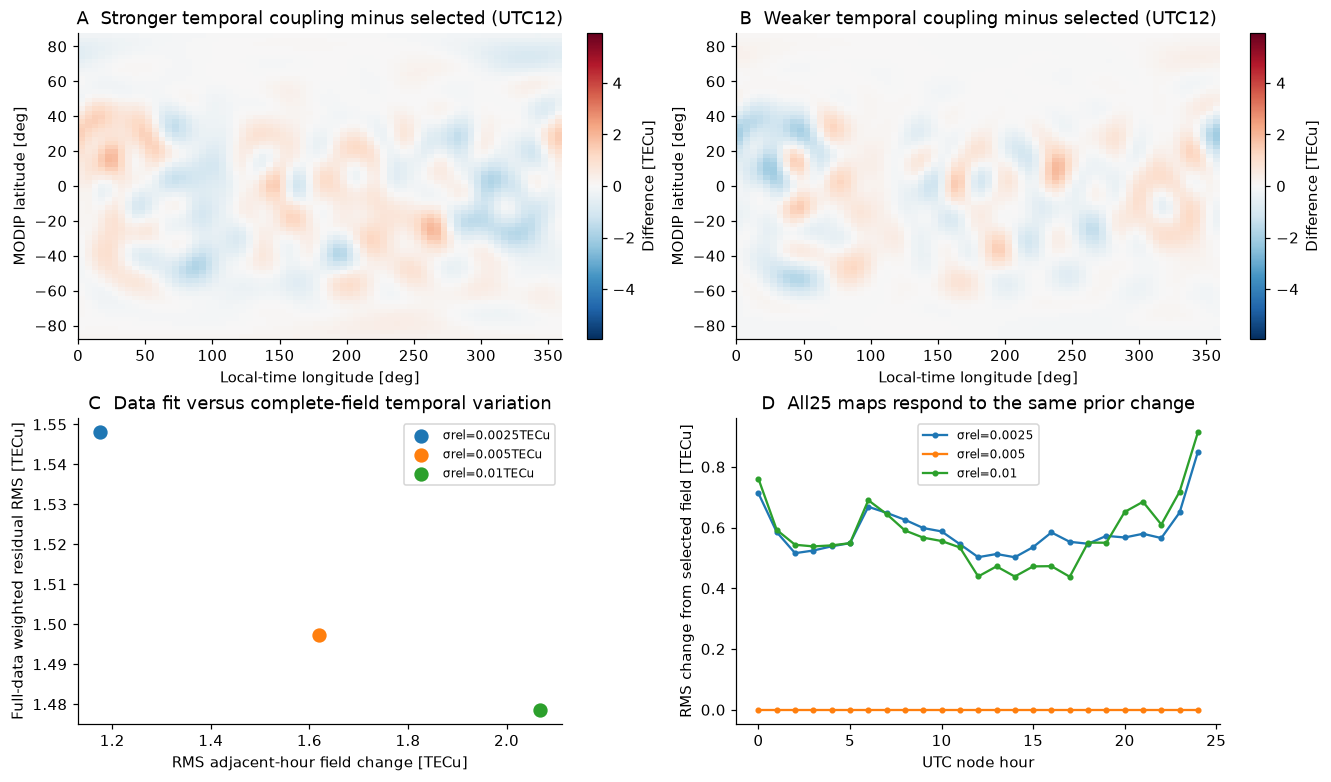

{
  "0.0025": {
    "weighted_rms": 1.5480398926484227,
    "hourly_roughness": 1.1753277819512045
  },
  "0.005": {
    "weighted_rms": 1.497351780662863,
    "hourly_roughness": 1.6197487188310353
  },
  "0.01": {
    "weighted_rms": 1.4786077611427093,
    "hourly_roughness": 2.0669545510142213
  }
}


In [6]:
base_precision=temporal_precision();sensitivity={};sensitivity_predictions={}
for sigma in [.0025,.005,.01]:
 if sigma==.005:
  result=fresh;field=maps;model=pred
 else:
  changed=N.copy();changed-=base_precision;changed+=temporal_precision(sigma_rel=sigma)
  result=solve_system(changed,b,rPr,dof);field=render_maps(result['coefficients']);model=predict(result['coefficients'],data)
  del changed
 sensitivity[str(sigma)]={'maps':field,'coefficients':result['coefficients'],
  'weighted_rms':residual_metrics(model,data)['weighted_rms_TECu'],
  'hourly_roughness':float(np.sqrt(np.mean(np.diff(field,axis=0)**2)))}
 sensitivity_predictions[str(sigma)]=model
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
limit=max(float(abs(sensitivity['0.0025']['maps']-maps).max()),float(abs(sensitivity['0.01']['maps']-maps).max()))
for a,key,title in [(ax[0,0],'0.0025','A  Stronger temporal coupling minus selected'),(ax[0,1],'0.01','B  Weaker temporal coupling minus selected')]:
 diff=sensitivity[key]['maps'][12]-maps[12];im=a.imshow(diff,extent=[0,360,-87.5,87.5],aspect='auto',norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),cmap='RdBu_r');fig.colorbar(im,ax=a,label='Difference [TECu]');a.set(title=title+' (UTC12)',xlabel='Local-time longitude [deg]',ylabel='MODIP latitude [deg]')
for key,value in sensitivity.items():
 ax[1,0].scatter(value['hourly_roughness'],value['weighted_rms'],s=70,label=f'σrel={key}TECu')
ax[1,0].set(title='C  Data fit versus complete-field temporal variation',xlabel='RMS adjacent-hour field change [TECu]',ylabel='Full-data weighted residual RMS [TECu]');ax[1,0].legend(fontsize=8)
for key,value in sensitivity.items():
 ax[1,1].plot(np.arange(25),np.sqrt(np.mean((value['maps']-maps)**2,axis=(1,2))),marker='o',ms=3,label=f'σrel={key}')
ax[1,1].set(title='D  All25 maps respond to the same prior change',xlabel='UTC node hour',ylabel='RMS change from selected field [TECu]');ax[1,1].legend(fontsize=8)
save_figure(fig,FIG,'figure6_temporal_sensitivity');plt.show()
print(json.dumps({k:{name:v for name,v in value.items() if name not in ['maps','coefficients']} for k,value in sensitivity.items()},indent=2))


## 6. Conclusion: a validated conditional field with visible limitations

The entire real day is reconstructed and evaluated. Numerical agreement with two independent qualified original runs validates extraction; all-ray residuals distinguish the result from zero, uniform and wrong-time controls. The small negative value outside the selected LCP rows is retained and displayed. Temporal-prior sensitivity makes interpolation uncertainty visible instead of claiming every map feature is independently measured.

The real residual is much larger than the selected0.02TECu weighting scale. Shared-reference correlation, author decimation without smoothing, uneven coverage and a one-shell model limit physical accuracy. No independent electron-content truth is supplied, and the article's other acquisition cases are not relabeled as this result. The final cell runs the independent standalone Judge and saves numeric sources for all six actual figure groups. No newly generated synthetic observations occur in this notebook.

Method source: Padokhin et al., *Phase-Difference Approach for GNSS Global Ionospheric Total Electron Content Mapping*, Radiophysics and Quantum Electronics65,481–495(2023), DOI:10.1007/s11141-023-10230-6. The source correction, executable preprocessing difference and actual test-package acquisition are qualified above; this is not a claim of unchanged full-paper reproduction.

In [7]:
spec=importlib.util.spec_from_file_location('gnss_independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert exit_code==0
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
np.savez(ROOT/'notebooks/reference_outputs/cleaned_outputs.npz',reconstruction=maps[None],coefficients=fresh['coefficients'],predicted=pred)
sources={'coverage':coverage,'reference_time_counts':pair_counts,'hour_ray_count':ray_hour,
 'maps_fresh':maps,'maps_original':original['qualified'],'maps_difference':delta,
 'map_ncc':ncc,'map_nrmse':nrmse,'maps_unconstrained':uncon_maps,
 'initial_negative':initial_negative,'new_negative':new_negative,'observed':data['rhs'],
 'predicted_fresh':pred,'predicted_unconstrained':pred_uncon,'predicted_wrong_time':pred_wrong,
 'predicted_uniform':pred_uniform,'weights':w,'hour_residual_rms':np.asarray(hour_rms)}
for key,value in sensitivity.items():
 sources['sensitivity_maps_'+key]=value['maps'];sources['sensitivity_coefficients_'+key]=value['coefficients']
 sources['sensitivity_prediction_'+key]=sensitivity_predictions[key]
np.savez(FIG/'plot_sources.npz',**sources)
metrics={'environment':environment,'active_full_runtime_seconds':active_runtime,
 'ncc_min':float(ncc.min()),'nrmse_max':float(nrmse.max()),'all_observation_comparisons':comparison_metrics,
 'minimum_TECu':float(maps.min()),'new_negative_count':int(new_negative.sum()),
 'sensitivity':{k:{name:v for name,v in value.items() if name not in ['maps','coefficients']} for k,value in sensitivity.items()},'judge':report}
(FIG/'plot_metrics.json').write_text(json.dumps(metrics,indent=2,allow_nan=False),encoding='utf8')
print('All six computed figure groups and numeric sources saved:',FIG)


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_min": 0.9999999999999999,
    "nrmse_max": 7.278529375998845e-15,
    "forward_weighted_rms_TECu": 1.497351780662864
  },
  "thresholds": {
    "ncc_min": {
      "comparison": ">=",
      "boundary": 0.999999999999
    },
    "nrmse_max": {
      "comparison": "<=",
      "boundary": 2.9645042444036815e-08
    },
    "forward_weighted_rms_TECu": {
      "comparison": "<=",
      "boundary": 1.5272988162761219
    }
  },
  "errors": []
}
All six computed figure groups and numeric sources saved: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch7_20261022\groups\astro_earth_mech\earth_reserve_screen\figures
